In [6]:
# Import-fix / M4
import sys, os
from pathlib import Path


WORK    = Path(r"D:\Projects\MediLens")
TRAINER = WORK / "EasyOCR" / "trainer"
config_path = TRAINER / "config_files" / "medical_prescription.yaml"
RESULTS = WORK / "results"; RESULTS.mkdir(exist_ok=True)
MODELS  = WORK / "models";  MODELS.mkdir(exist_ok=True)

for k in ("utils", "model", "dataset", "test", "train"):
    sys.modules.pop(k, None)
sys.path.insert(0, str(TRAINER))
os.chdir(TRAINER)

import utils
print(utils.__file__)                          # must end with ...\trainer\utils.py
from utils import AttrDict, CTCLabelConverter

D:\Projects\MediLens\EasyOCR\trainer\utils.py


In [9]:
# Detector set-up / Cell D1
import gc, cv2, numpy as np, torch, easyocr
import matplotlib.pyplot as plt
from PIL import Image

from PIL import ImageOps
def load_rgb(p):
    """open an image as a person sees it: apply the EXIF rotation tag, which PIL ignores by default"""
    return ImageOps.exif_transpose(Image.open(p)).convert("RGB")

from PIL import ImageOps
def load_rgb(p):
    """open an image as a person sees it: apply the EXIF rotation tag, which PIL ignores by default"""
    return ImageOps.exif_transpose(Image.open(p)).convert("RGB")

FULL_DIR = WORK / "Data" / "full_prescriptions"      # <- put 5-10 full prescription photos here
FULL_DIR.mkdir(parents=True, exist_ok=True)
DET_OUT = RESULTS / "detection"; DET_OUT.mkdir(exist_ok=True)
N_IMAGES = 8

full_paths = sorted(p for p in FULL_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})[:N_IMAGES]
print(len(full_paths), "full prescriptions in", FULL_DIR)
assert full_paths, f"copy a few full prescription photos into {FULL_DIR} first"

# two merge settings: EasyOCR defaults, and one that merges words into lines less eagerly
SETTINGS = {
    "default":      dict(),
    "less_merging": dict(width_ths=0.2, ycenter_ths=0.3, height_ths=0.3, add_margin=0.05),
}

det_reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)

def detect_boxes(img_rgb, **kw):
    """returns axis-aligned boxes [x0, y0, x1, y1] from EasyOCR's CRAFT detector"""
    h_list, f_list = det_reader.detect(img_rgb, **kw)
    boxes = [[int(x0), int(y0), int(x1), int(y1)] for x0, x1, y0, y1 in h_list[0]]
    for poly in f_list[0]:                           # tilted boxes: take their bounding rectangle
        p = np.array(poly)
        boxes.append([int(p[:, 0].min()), int(p[:, 1].min()), int(p[:, 0].max()), int(p[:, 1].max())])
    boxes = [[max(0, a), max(0, b), c, d] for a, b, c, d in boxes]
    return sorted(boxes, key=lambda b: (b[1], b[0]))

def draw(img_rgb, boxes):
    out = img_rgb.copy()
    for i, (x0, y0, x1, y1) in enumerate(boxes):
        cv2.rectangle(out, (x0, y0), (x1, y1), (255, 0, 0), 2)
        cv2.putText(out, str(i), (x0, max(12, y0 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    return out

8 full prescriptions in D:\Projects\MediLens\Data\full_prescriptions


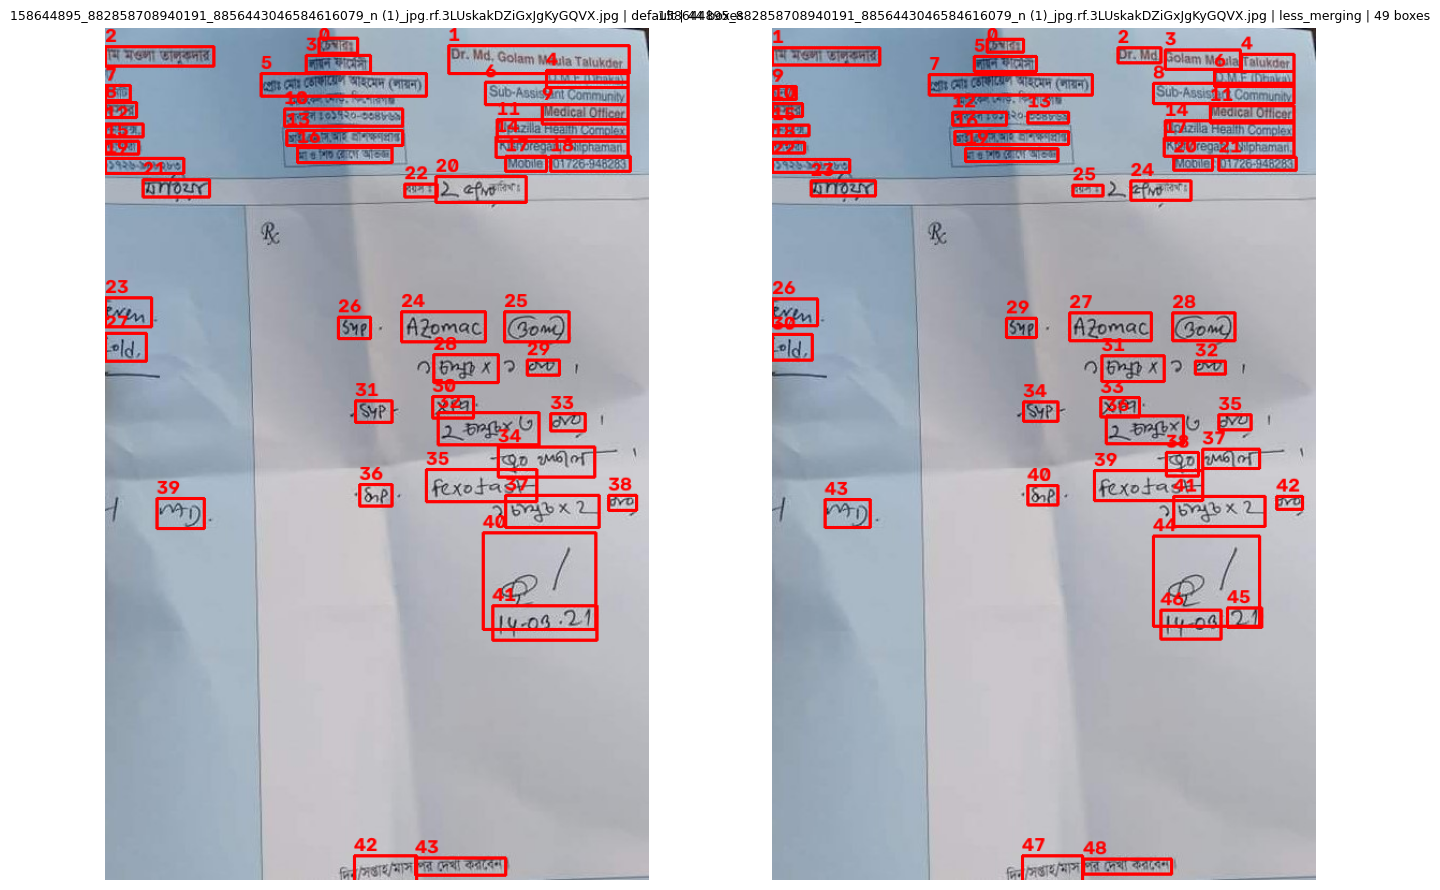

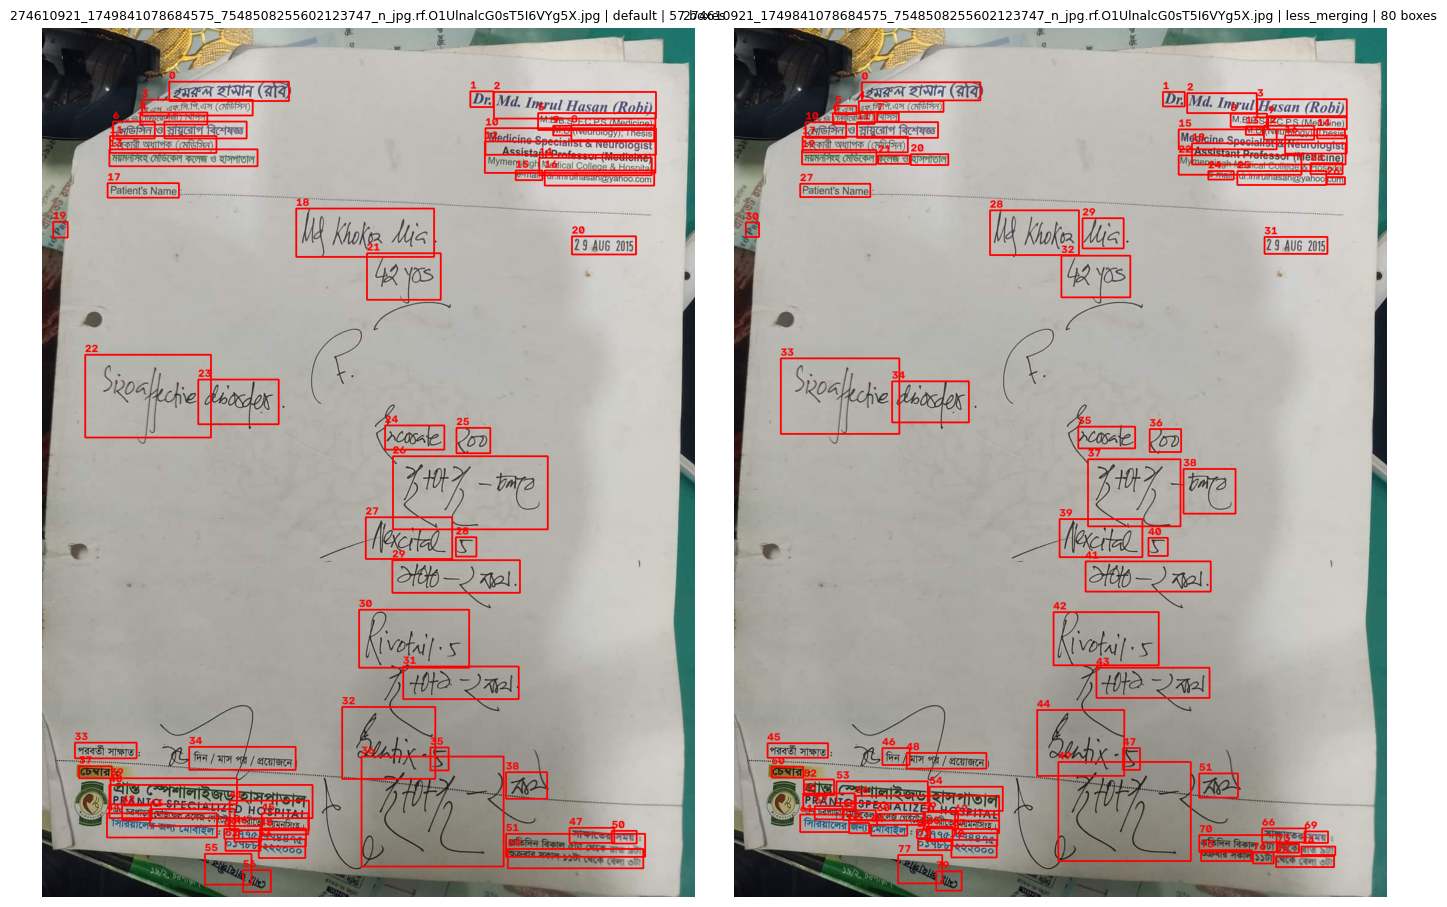

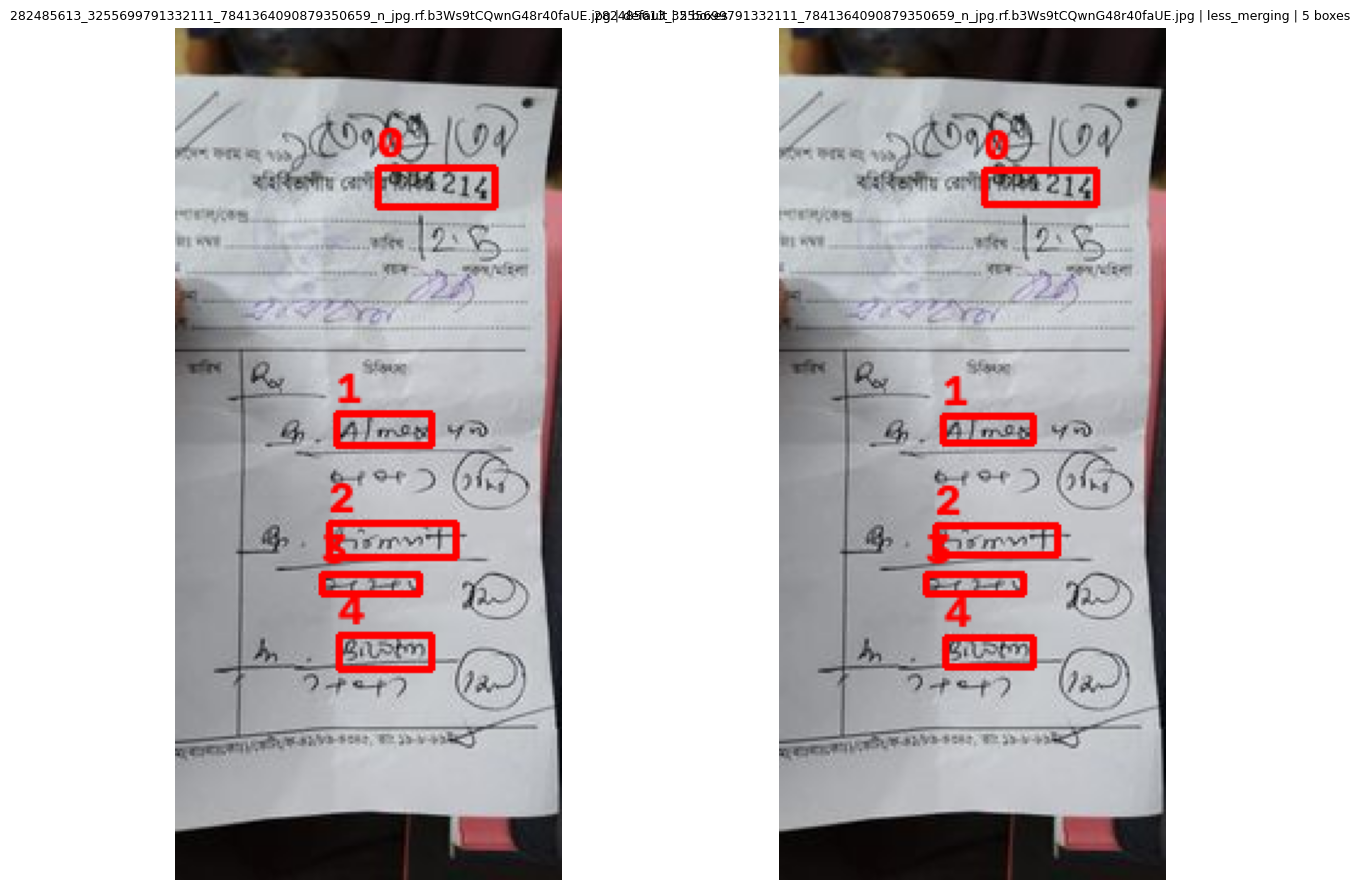

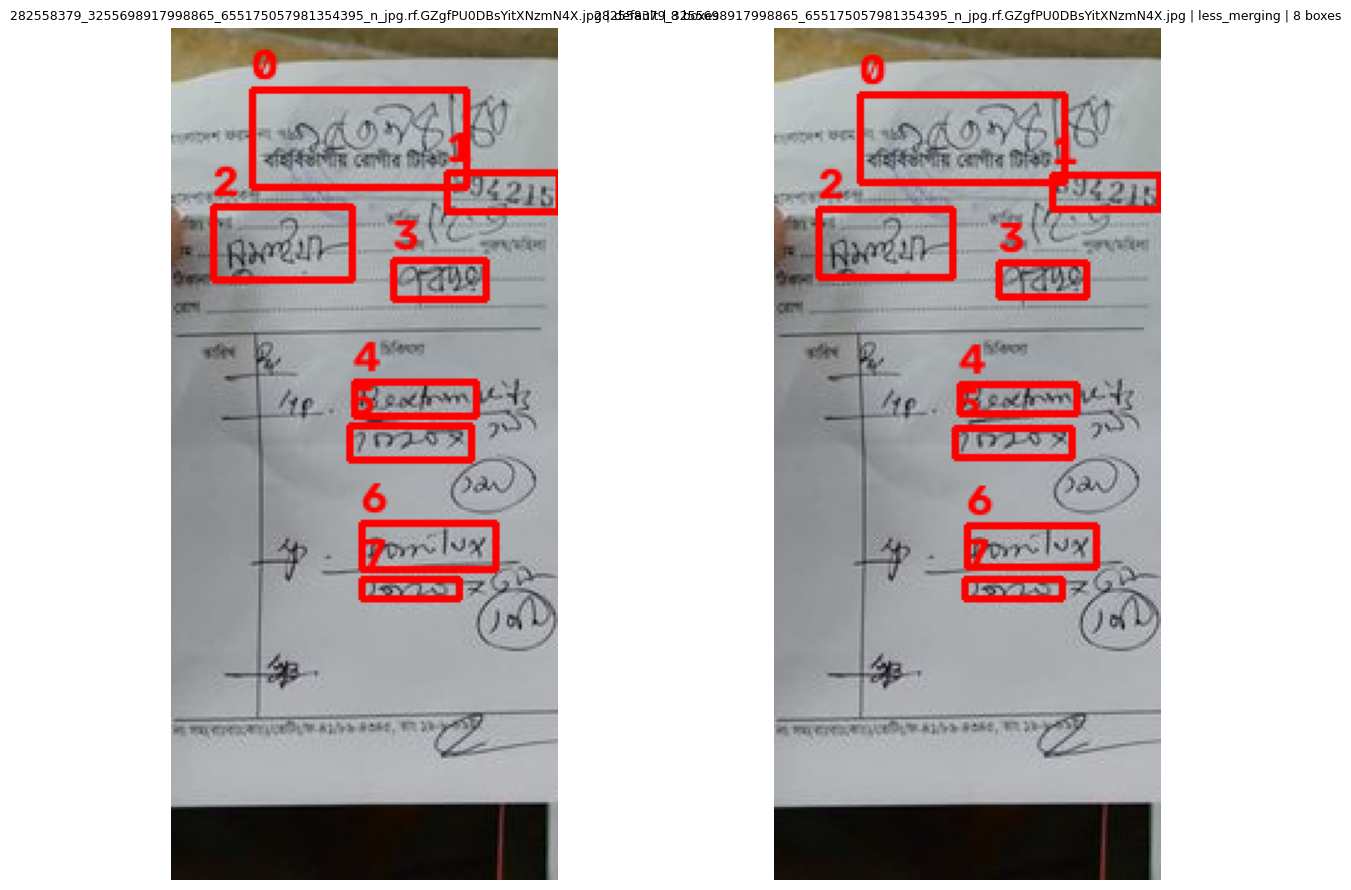

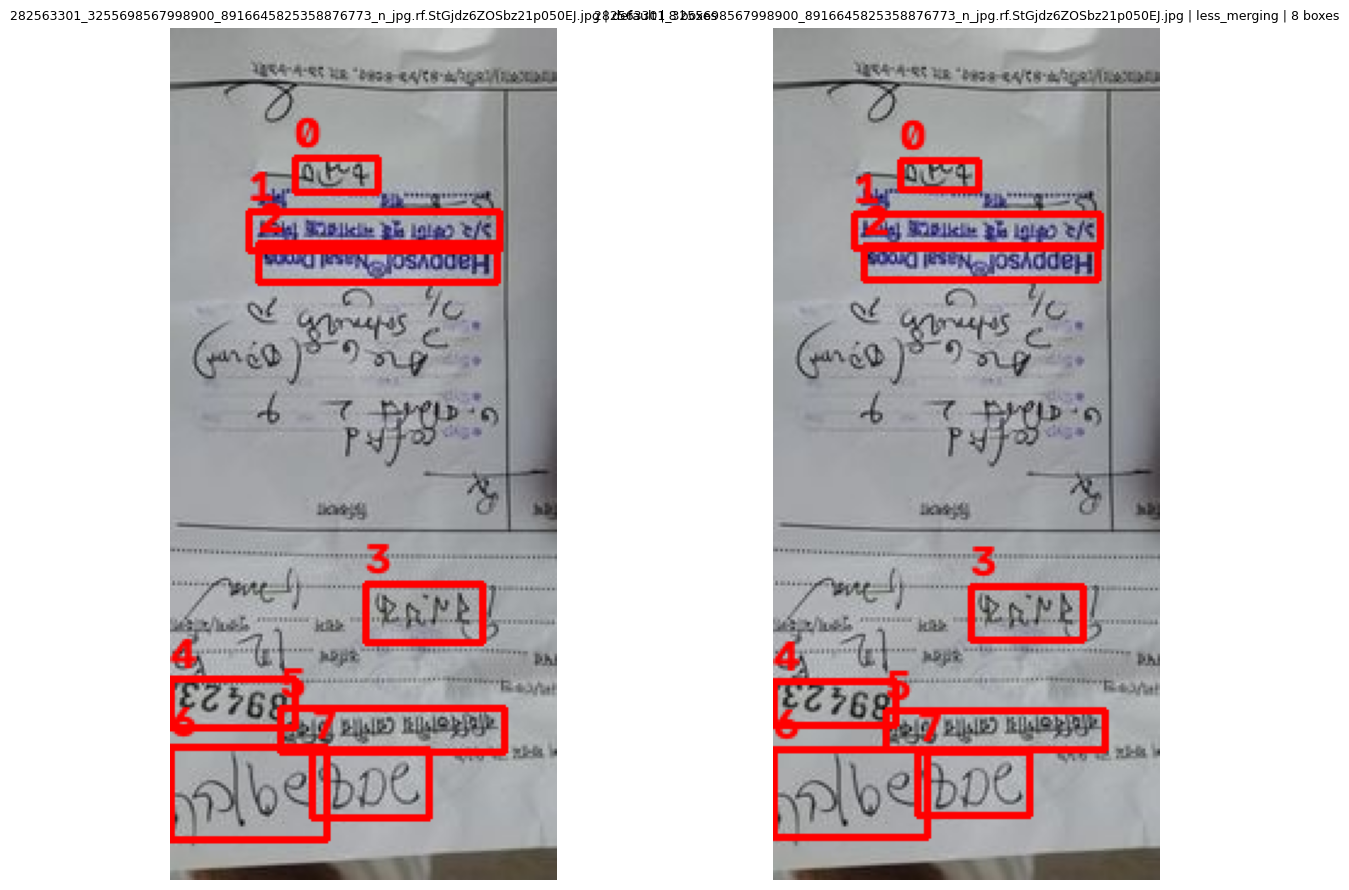

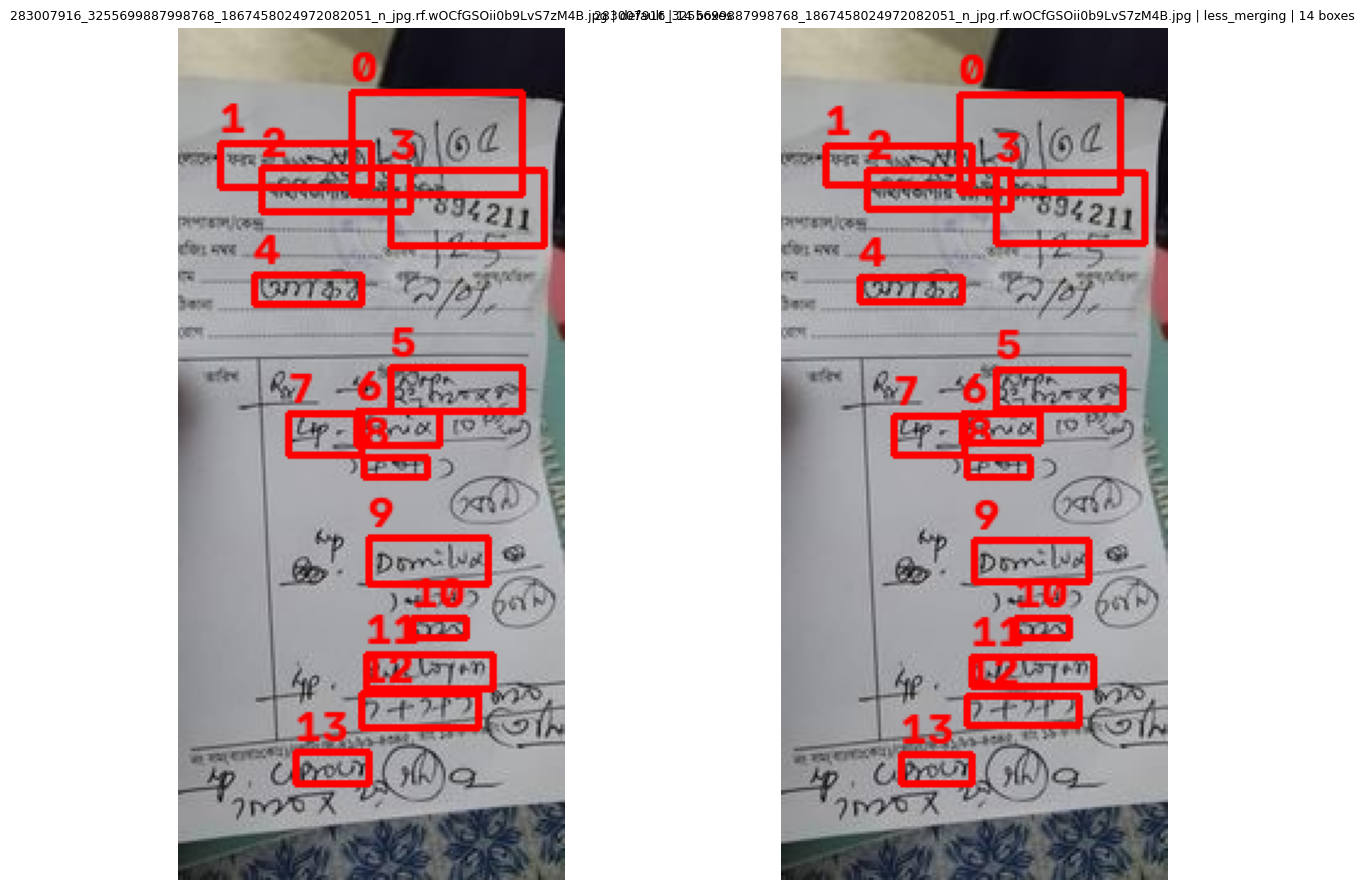

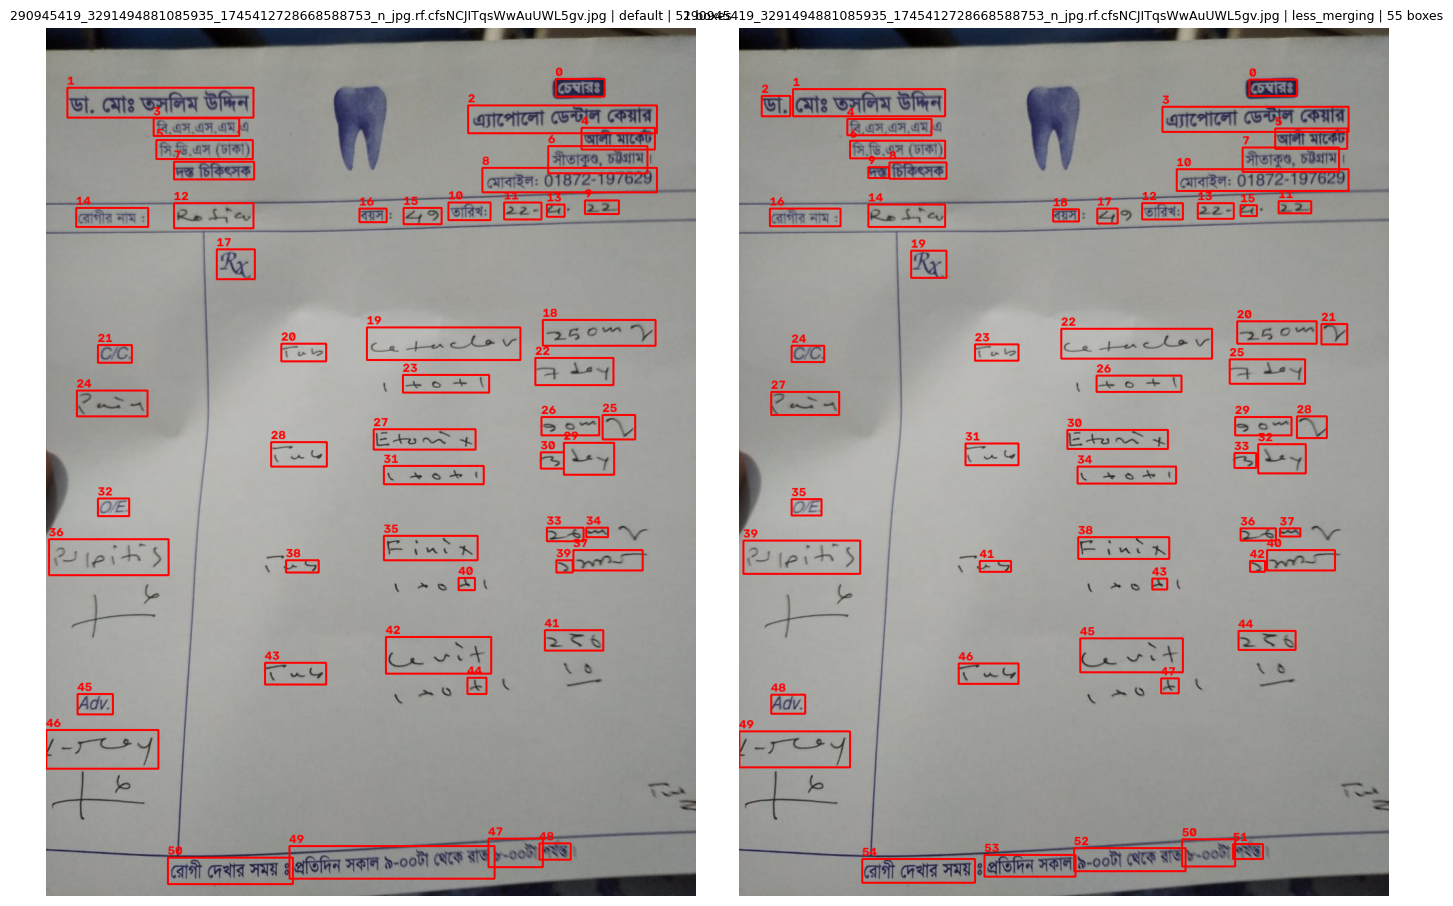

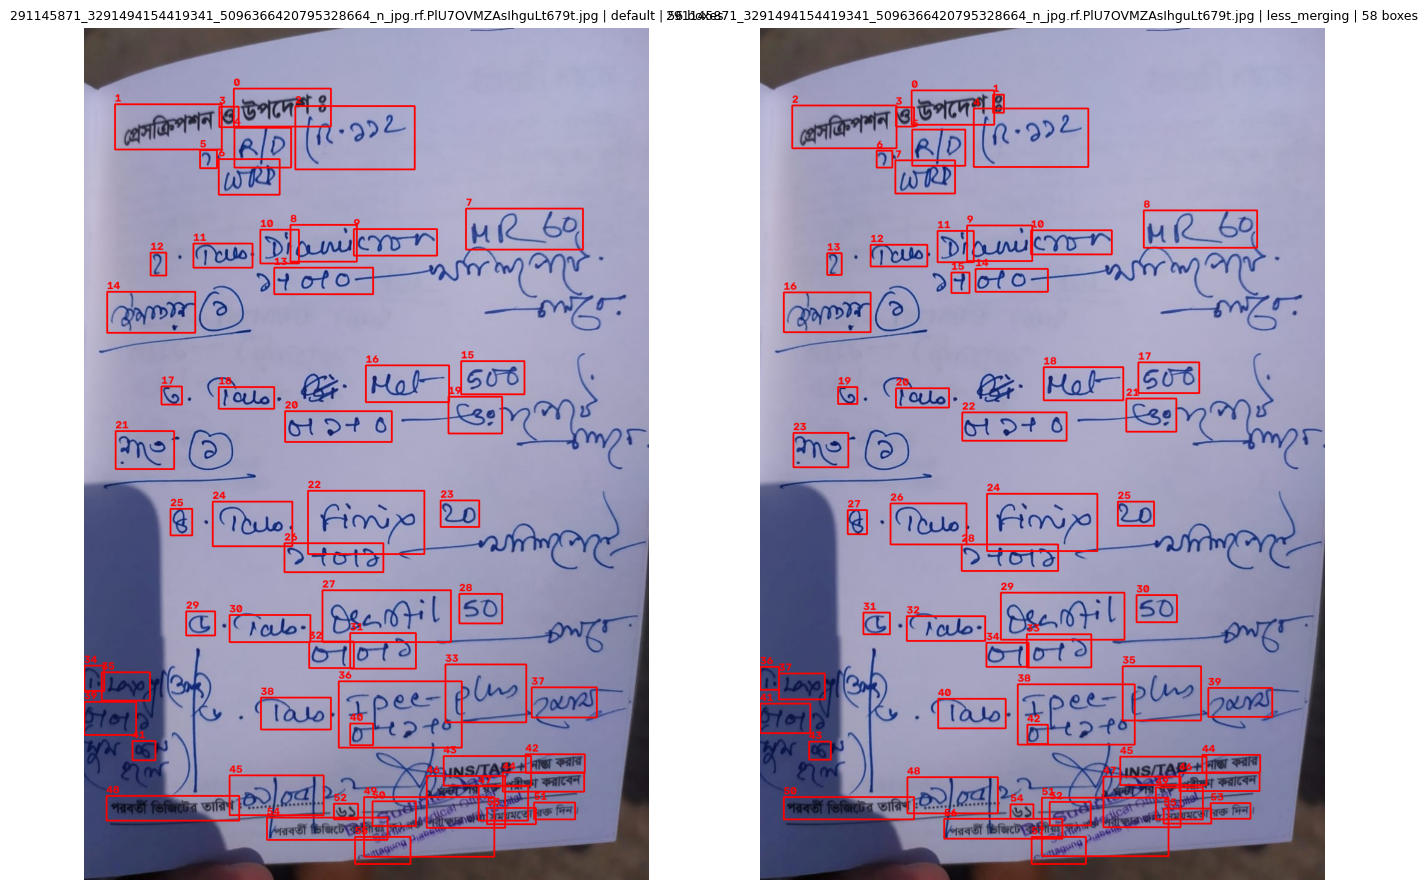

                                                                              image      setting  boxes  median height px  max height px
158644895_882858708940191_8856443046584616079_n (1)_jpg.rf.3LUskakDZiGxJgKyGQVX.jpg      default     44                19             90
158644895_882858708940191_8856443046584616079_n (1)_jpg.rf.3LUskakDZiGxJgKyGQVX.jpg less_merging     49                17             84
   274610921_1749841078684575_7548508255602123747_n_jpg.rf.O1UlnalcG0sT5I6VYg5X.jpg      default     57                32            182
   274610921_1749841078684575_7548508255602123747_n_jpg.rf.O1UlnalcG0sT5I6VYg5X.jpg less_merging     80                26            164
   282485613_3255699791332111_7841364090879350659_n_jpg.rf.b3Ws9tCQwnG48r40faUE.jpg      default      5                14             16
   282485613_3255699791332111_7841364090879350659_n_jpg.rf.b3Ws9tCQwnG48r40faUE.jpg less_merging      5                12             14
    282558379_3255698917998865_6551750579

In [ ]:
# Detector comparison grid / Cell D2
import pandas as pd

summary = []
for p in full_paths:
    img = np.array(load_rgb(p))
    fig, axes = plt.subplots(1, len(SETTINGS), figsize=(7 * len(SETTINGS), 9))
    for ax, (name, kw) in zip(np.atleast_1d(axes), SETTINGS.items()):
        boxes = detect_boxes(img, **kw)
        hs = np.array([b[3] - b[1] for b in boxes]) if boxes else np.array([0])
        summary.append({"image": p.name, "setting": name, "boxes": len(boxes),
                        "median height px": int(np.median(hs)), "max height px": int(hs.max())})
        ax.imshow(draw(img, boxes)); ax.axis("off"); ax.set_title(f"{p.name} | {name} | {len(boxes)} boxes", fontsize=9)
    plt.tight_layout()
    fig.savefig(DET_OUT / f"{p.stem}_detection.png", dpi=150)
    plt.show()

summ = pd.DataFrame(summary)
print(summ.to_string(index=False))
summ.to_csv(RESULTS / "results_detection_pretrained.csv", index=False)
# Judge by eye per image: fragmented (one word split in several boxes), merged (two lines in one box), missed lines.
# Very tall boxes (max height far above median) usually mean merged lines.

In [ ]:
# Detect -> crop -> read preview / Cell D3
# Runs the existing WordReader on every detected box, to see what the full pipeline would output.
APP = WORK / "app"
sys.path.insert(0, str(APP))
import word_reader as wr

SETTING = "default"          # change to "less_merging" to compare
PAD = 4                      # px of context added around each box
MIN_H, MIN_W = 12, 24        # skip specks

del det_reader; gc.collect(); torch.cuda.empty_cache()   # free the GPU before loading the recognizer
det_reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)
word_rd = wr.WordReader()

rows = []
for p in full_paths:
    img = np.array(load_rgb(p))
    H, W = img.shape[:2]
    boxes = [b for b in detect_boxes(img, **SETTINGS[SETTING]) if b[3] - b[1] >= MIN_H and b[2] - b[0] >= MIN_W]
    crops = [Image.fromarray(img[max(0, y0 - PAD):min(H, y1 + PAD), max(0, x0 - PAD):min(W, x1 + PAD)])
             for x0, y0, x1, y1 in boxes]
    if not crops:
        continue
    for i, (b, r) in enumerate(zip(boxes, word_rd.read(crops))):
        rows.append({"image": p.name, "box": i, "bbox": b, "raw": r.raw, "name": r.name,
                     "form": r.form, "margin": round(r.margin, 2), "flagged": r.flagged})

preview = pd.DataFrame(rows)
print(preview.groupby("image").agg(boxes=("box", "size"), flagged=("flagged", "sum"))
             .assign(accepted=lambda d: d["boxes"] - d["flagged"]))
print(preview.to_string(index=False))
preview.to_csv(RESULTS / f"detect_read_preview_{SETTING}.csv", index=False)


No Transformation module specified
                                                    boxes  flagged  accepted
image                                                                       
158644895_882858708940191_8856443046584616079_n...     43       41         2
274610921_1749841078684575_7548508255602123747_...     57       55         2
282485613_3255699791332111_7841364090879350659_...      4        4         0
282558379_3255698917998865_655175057981354395_n...      7        7         0
282563301_3255698567998900_8916645825358876773_...      8        8         0
283007916_3255699887998768_1867458024972082051_...     12       12         0
290945419_3291494881085935_1745412728668588753_...     51       50         1
291145871_3291494154419341_5096366420795328664_...     56       55         1
                                                                              image  box                   bbox                           raw               name    form  margin  flagged
158644895

In [10]:
# Detector vs ground truth / Cell D4  (04_detection)
import json
import pandas as pd

def iou_matrix(A, B):
    A = np.asarray(A, float).reshape(-1, 4); B = np.asarray(B, float).reshape(-1, 4)
    if len(A) == 0 or len(B) == 0:
        return np.zeros((len(A), len(B)))
    ix0 = np.maximum(A[:, None, 0], B[None, :, 0]); iy0 = np.maximum(A[:, None, 1], B[None, :, 1])
    ix1 = np.minimum(A[:, None, 2], B[None, :, 2]); iy1 = np.minimum(A[:, None, 3], B[None, :, 3])
    inter = np.clip(ix1 - ix0, 0, None) * np.clip(iy1 - iy0, 0, None)
    area = lambda X: (X[:, 2] - X[:, 0]) * (X[:, 3] - X[:, 1])
    return inter / (area(A)[:, None] + area(B)[None, :] - inter + 1e-9)

def centers_inside(P, Q):
    """matrix [len(P), len(Q)]: is the centre of P[i] inside Q[j]?"""
    P = np.asarray(P, float).reshape(-1, 4); Q = np.asarray(Q, float).reshape(-1, 4)
    cx = ((P[:, 0] + P[:, 2]) / 2)[:, None]; cy = ((P[:, 1] + P[:, 3]) / 2)[:, None]
    return (cx >= Q[None, :, 0].reshape(1, -1)) & (cx <= Q[None, :, 2].reshape(1, -1)) & \
           (cy >= Q[None, :, 1].reshape(1, -1)) & (cy <= Q[None, :, 3].reshape(1, -1))

def match_stats(G, D, thr=0.5):
    M = iou_matrix(G, D)                                                    # [GT, detections]
    ok = len(G) and len(D)
    return {"best_iou": M.max(1) if M.size else np.zeros(len(G)),
            "split": (centers_inside(D, G).sum(0) >= 2) if ok else np.zeros(len(G), bool),    # GT cut into 2+ boxes
            "merged": (centers_inside(G, D).sum(0) >= 2) if ok else np.zeros(len(D), bool),   # box covering 2+ GT lines
            "det_matches": (M.max(0) >= thr) if M.size else np.zeros(len(D), bool),
            "det_in_gt": centers_inside(D, G).any(1) if ok else np.zeros(len(D), bool)}

# ---- ground truth (COCO export placed under FULL_DIR) ----
ann_files = sorted(FULL_DIR.rglob("_annotations.coco.json"))
assert ann_files, f"export the Roboflow set as COCO into {FULL_DIR} (needs _annotations.coco.json)"
rows = []
for af in ann_files:
    coco = json.loads(af.read_text(encoding="utf-8"))
    cats = {c["id"]: c["name"] for c in coco["categories"]}
    imgs = {i["id"]: i for i in coco["images"]}
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        im = imgs[a["image_id"]]
        rows.append({"split": af.parent.name, "path": str(af.parent / im["file_name"]),
                     "x0": x, "y0": y, "x1": x + w, "y1": y + h, "cls": cats[a["category_id"]]})
gt = pd.DataFrame(rows)
print(len(gt), "GT boxes |", gt["path"].nunique(), "images |", gt["cls"].nunique(), "classes")
print("boxes per image: median", int(gt.groupby("path").size().median()),
      "| GT box height px: median", int((gt["y1"] - gt["y0"]).median()))
print(gt["cls"].value_counts().head(20).to_string())

# ---- detector recall, fragmentation, merging ----
MAX_IMG = 100                      # None = all images (about 2 s per image per setting)
res = {k: {"best": [], "split": [], "merged": [], "match": [], "in_gt": []} for k in SETTINGS}
for path in sorted(gt["path"].unique())[:MAX_IMG]:
    if not Path(path).exists():
        continue
    img = np.array(load_rgb(path))
    G = gt.loc[gt["path"] == path, ["x0", "y0", "x1", "y1"]].values
    for name, kw in SETTINGS.items():
        D = np.array(detect_boxes(img, **kw)).reshape(-1, 4)
        s = match_stats(G, D)
        for key, sk in (("best", "best_iou"), ("split", "split"), ("merged", "merged"),
                        ("match", "det_matches"), ("in_gt", "det_in_gt")):
            res[name][key].append(s[sk])

out = []
for name, r in res.items():
    best, split, merged, match, in_gt = (np.concatenate(r[k]) for k in ("best", "split", "merged", "match", "in_gt"))
    out.append({"setting": name, "GT boxes": len(best), "detections": len(match),
                "recall@0.5 %": round(100 * (best >= 0.5).mean(), 1),
                "recall@0.3 %": round(100 * (best >= 0.3).mean(), 1),
                "GT split in 2+ boxes %": round(100 * split.mean(), 1),
                "detections merging 2+ GT %": round(100 * merged.mean(), 1),
                "detections on a labelled line %": round(100 * in_gt.mean(), 1)})
det_eval = pd.DataFrame(out)
print(det_eval.to_string(index=False))
det_eval.to_csv(RESULTS / "results_detection_recall.csv", index=False)

1613 GT boxes | 378 images | 831 classes
boxes per image: median 4 | GT box height px: median 52
cls
Finix          28
Sergel         22
Maxpro         20
Pantonix       17
Algin          16
Diasulin       14
Clopid         13
Monas          11
Napa           11
Emistat        10
Thyrin         10
Maxpro Mups    10
Fexo           10
Viset          10
Reversair       9
remmo           9
Lijenta         8
Bopam           8
Myolax          8
Etorix          8
     setting  GT boxes  detections  recall@0.5 %  recall@0.3 %  GT split in 2+ boxes %  detections merging 2+ GT %  detections on a labelled line %
     default       371        4838          65.5          88.4                    11.6                         0.0                              8.0
less_merging       371        5922          64.4          87.9                    19.4                         0.0                              7.2


In [17]:
#check license
coco = json.loads(ann_files[0].read_text(encoding="utf-8"))
print(coco.get("info"), coco.get("licenses"))

{'year': '2026', 'version': 'dataset', 'description': 'Exported from roboflow.com', 'contributor': '', 'url': 'https://app.roboflow.com/datasets/doctors-prescription-fv20k/dataset', 'date_created': '2026-11-08T11:50:00+00:00'} [{'id': 1, 'url': 'https://creativecommons.org/licenses/by/4.0/', 'name': 'CC BY 4.0'}]


In [11]:
# Vocabulary coverage and name hygiene / Cell D5 
import re, yaml
sys.path.insert(0, str(WORK / "app"))
from prescription_parser import edit_distance

cfg = yaml.safe_load(config_path.read_text(encoding="utf-8"))
allowed = set(cfg["number"] + cfg["symbol"] + cfg["lang_char"])
app_vocab = [ln.strip() for ln in (WORK / "app" / "vocab.txt").read_text(encoding="utf-8").splitlines() if ln.strip()]
key = lambda s: re.sub(r"\s+", " ", s.strip().lower())
vocab_keys = {key(n) for n in app_vocab}

counts = gt["cls"].str.strip().value_counts()                  # boxes per Roboflow class name
names = pd.DataFrame({"name": counts.index, "boxes": counts.values})
names["key"] = names["name"].map(key)
names["in_vocab"] = names["key"].isin(vocab_keys)
names["bad_chars"] = names["name"].map(lambda n: "".join(sorted(set(n) - allowed)))
names["lower_start"] = names["name"].str[:1].str.islower()

def nearest(k, pool, max_d=2):
    hits = sorted((edit_distance(k, m), m) for m in pool if m != k and abs(len(m) - len(k)) <= max_d)
    return ", ".join([m for d, m in hits if d <= max_d][:3])

pool = sorted(vocab_keys | set(names["key"]))
def variant_of(k):                                              # "maxpro mups" vs "maxpro": same drug, extra word
    return ", ".join(m for m in pool if m != k and (k.startswith(m + " ") or m.startswith(k + " ")))[:80]
names["near"] = [(nearest(k, pool) + ", " + variant_of(k)).strip(", ") if not iv else ""
                 for k, iv in zip(names["key"], names["in_vocab"])]

tot_boxes = names["boxes"].sum()
print(f"current vocabulary: {len(vocab_keys)} names")
print(f"Roboflow classes already in vocabulary: {names['in_vocab'].sum()} of {len(names)} "
      f"({100 * names['in_vocab'].mean():.1f}% of classes, "
      f"{100 * names.loc[names['in_vocab'], 'boxes'].sum() / tot_boxes:.1f}% of boxes)")
print(f"classes with a single box: {(names['boxes'] == 1).sum()} | "
      f"characters the model cannot output: {(names['bad_chars'] != '').sum()} | "
      f"lower-case first letter: {names['lower_start'].sum()} | "
      f"new names within 2 edits of, or a variant of, another name: {(names['near'] != '').sum()}")

new = names[~names["in_vocab"]].copy()
new["ok_to_add"] = (new["bad_chars"] == "") & (~new["lower_start"]) & (new["near"] == "")
print("new names that pass the simple checks:", int(new["ok_to_add"].sum()), "| need a look:", int((~new["ok_to_add"]).sum()))
new.sort_values("boxes", ascending=False).to_csv(RESULTS / "vocab_candidates.csv", index=False)
print(new[~new["ok_to_add"]].sort_values("boxes", ascending=False).head(25)[["name", "boxes", "near", "bad_chars"]].to_string(index=False))

current vocabulary: 704 names
Roboflow classes already in vocabulary: 69 of 831 (8.3% of classes, 13.6% of boxes)
classes with a single box: 530 | characters the model cannot output: 0 | lower-case first letter: 1 | new names within 2 edits of, or a variant of, another name: 406
new names that pass the simple checks: 356 | need a look: 406
       name  boxes                            near bad_chars
      Finix     28             fixit, folix, sinex          
   Pantonix     17              pantocid, protonix          
      Algin     16                      atin, azin          
   Diasulin     14                         insulin          
     Clopid     13                          clomid          
      Viset     10              anset, d-set, nise          
    Emistat     10                          evista          
Maxpro Mups     10                          maxpro          
     Thyrin     10                          thyrox          
      remmo      9                          remo

In [24]:
print(names[names["key"].str.contains("fucid")])

Empty DataFrame
Columns: [name, boxes, key, in_vocab, bad_chars, lower_start, near]
Index: []


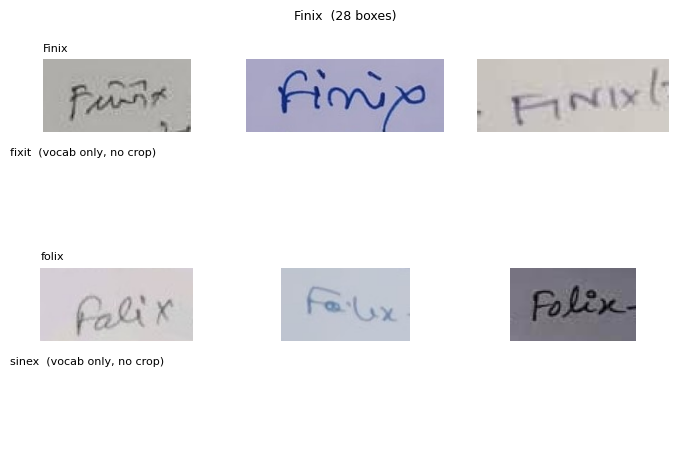

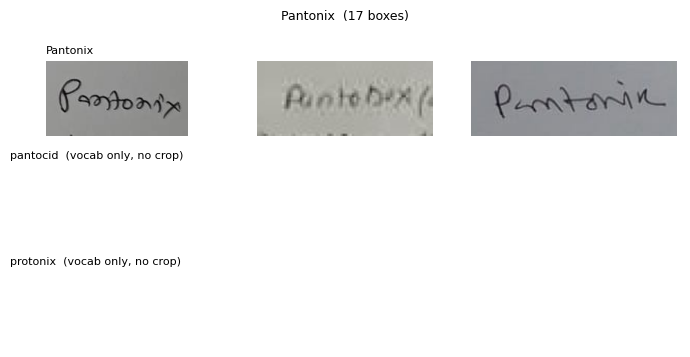

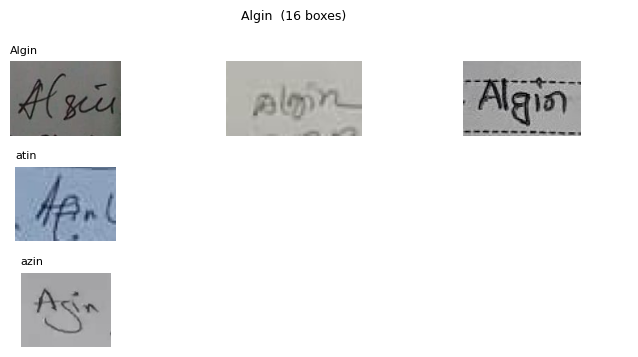

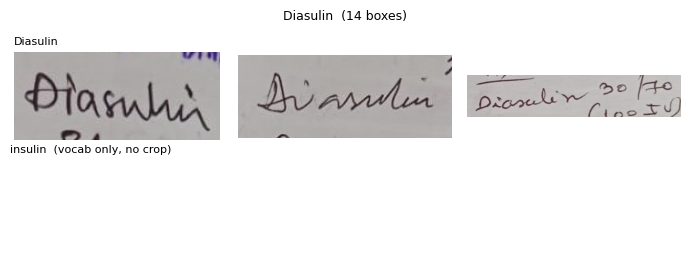

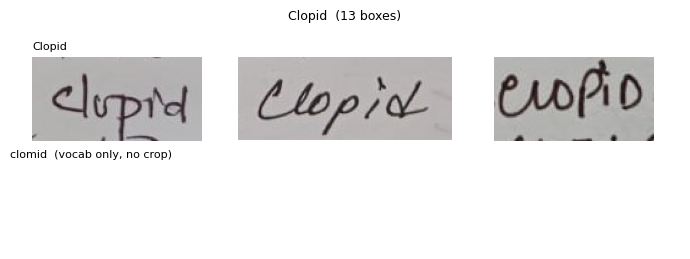

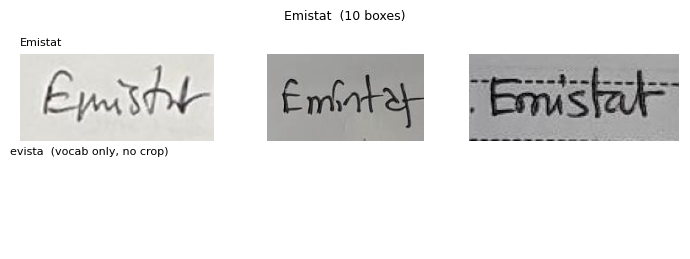

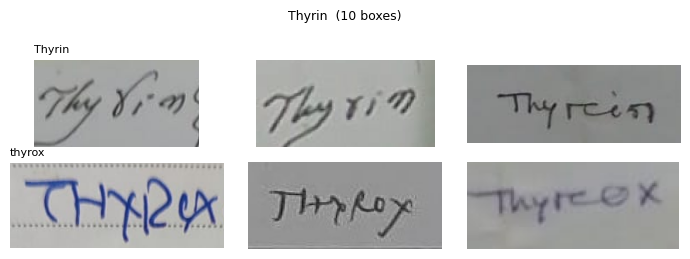

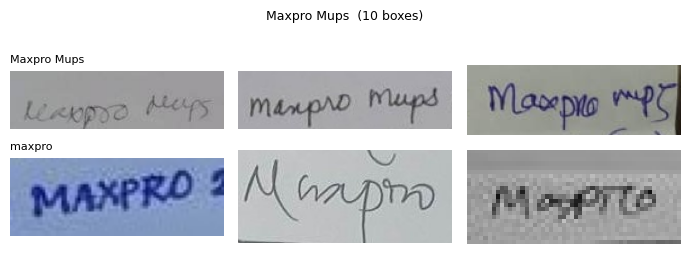

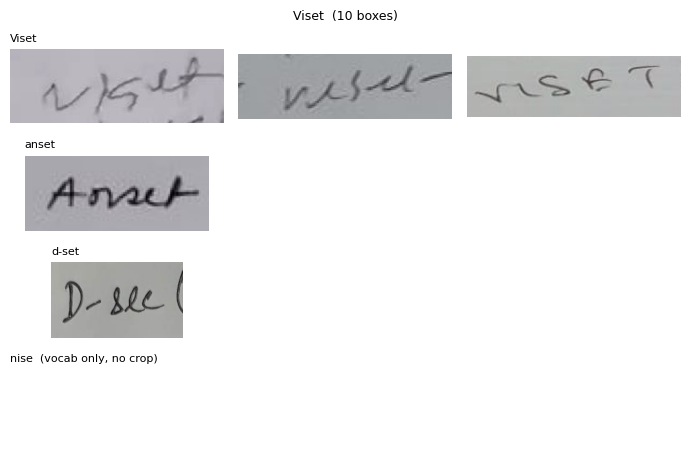

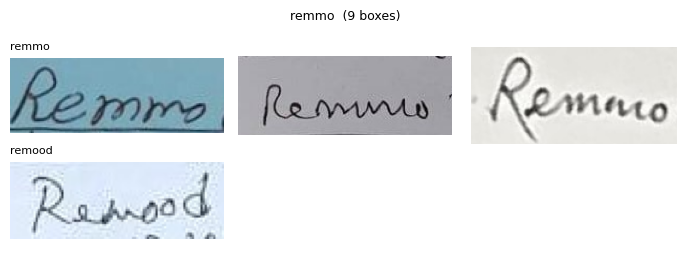

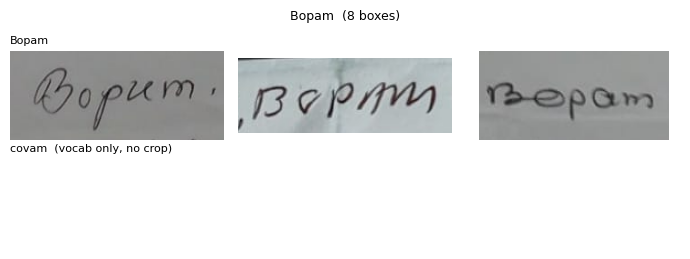

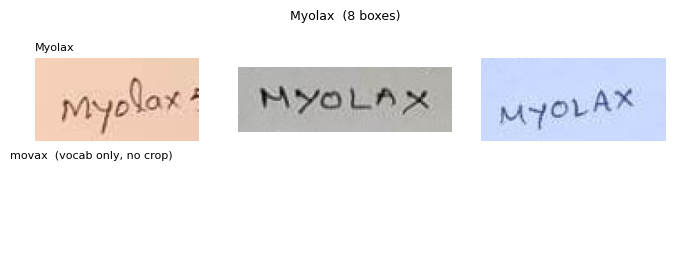

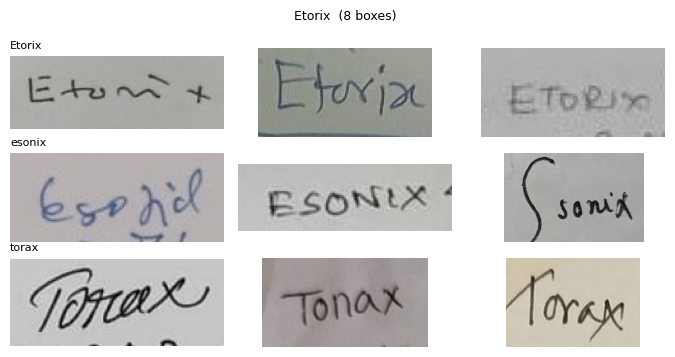

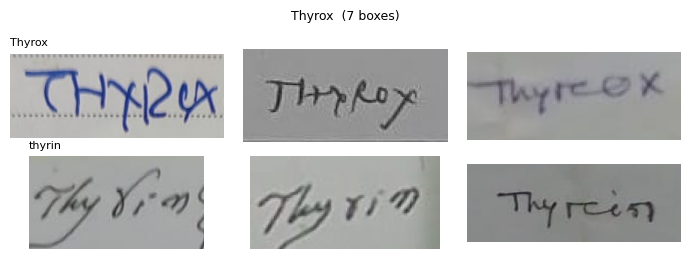

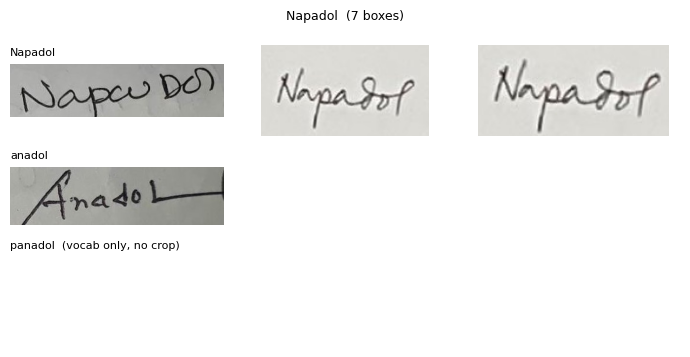

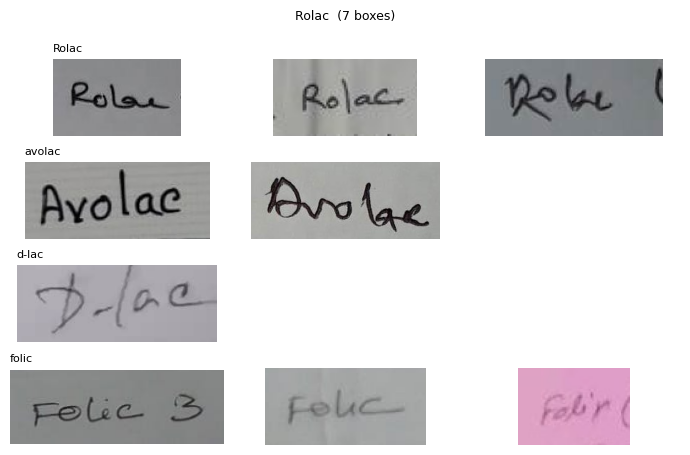

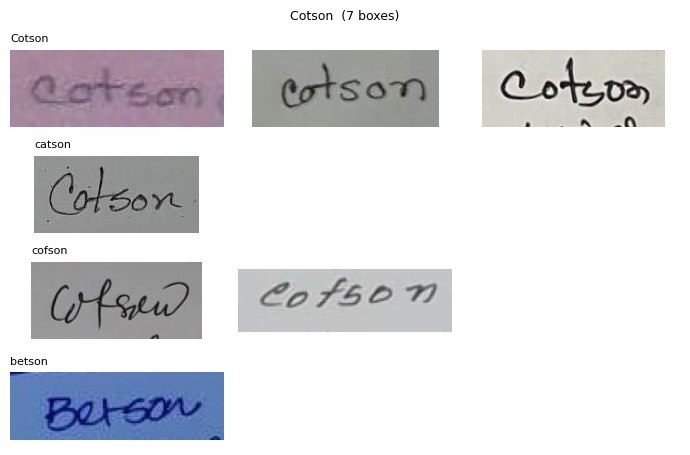

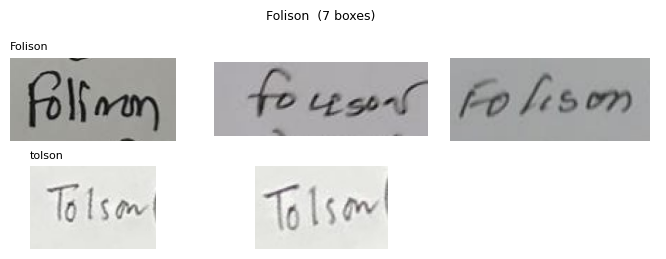

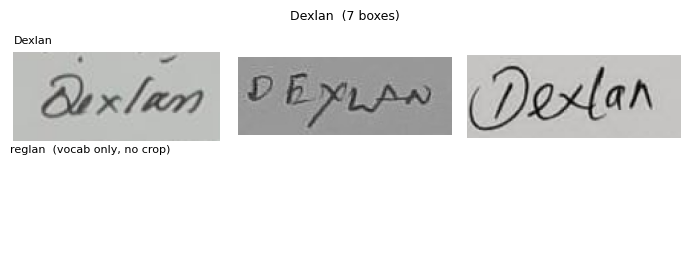

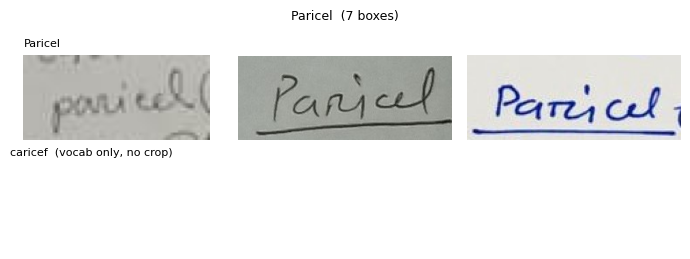

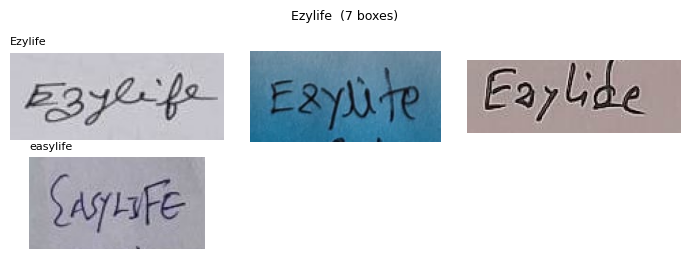

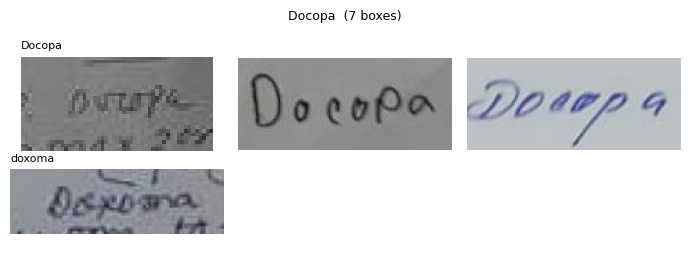

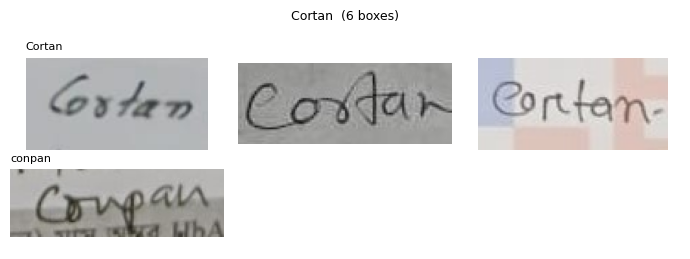

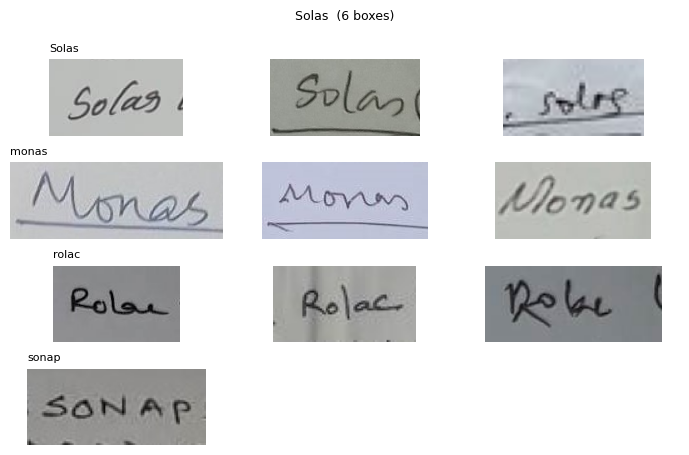

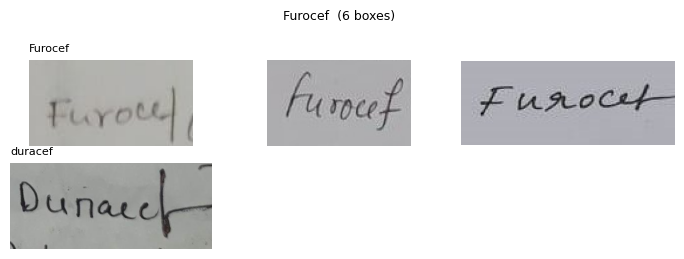

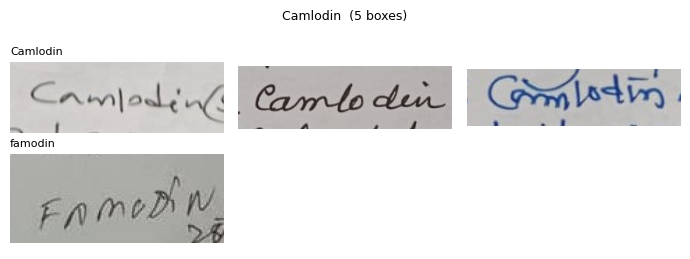

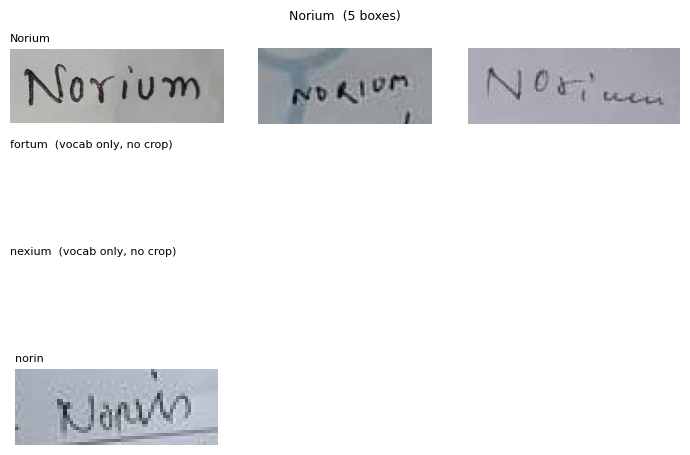

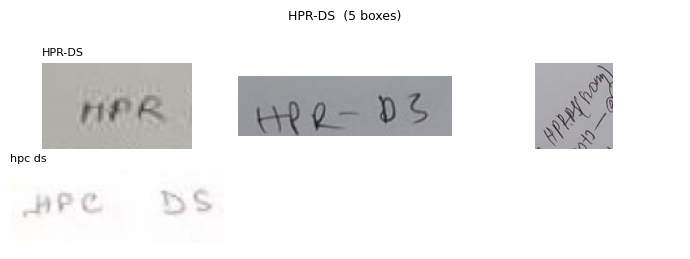

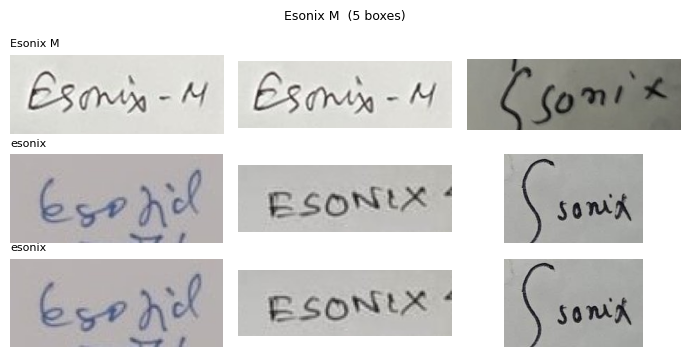

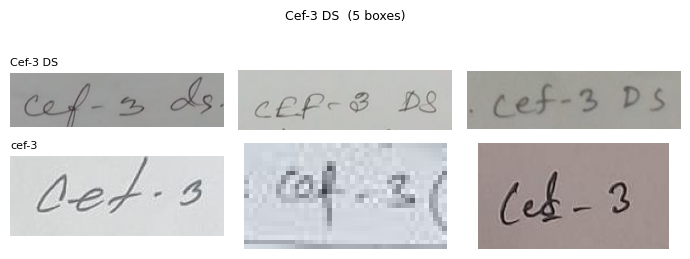

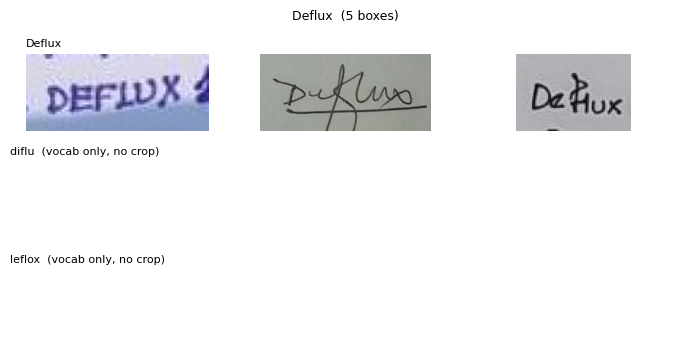

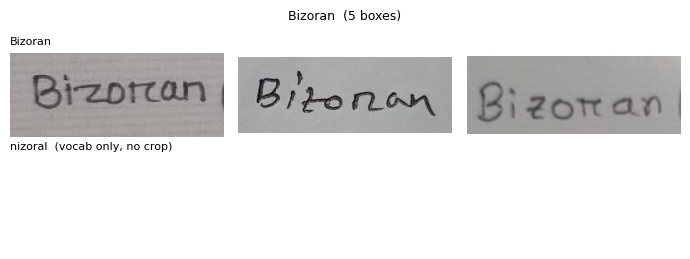

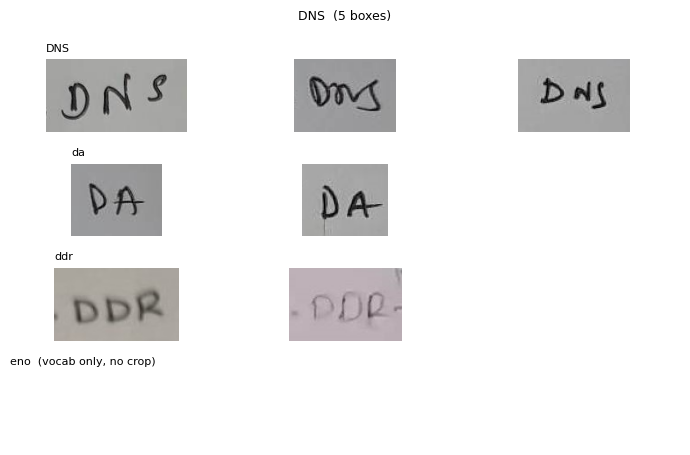

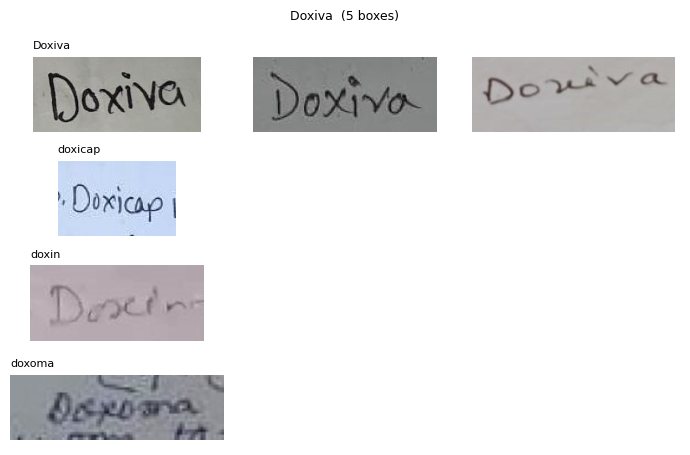

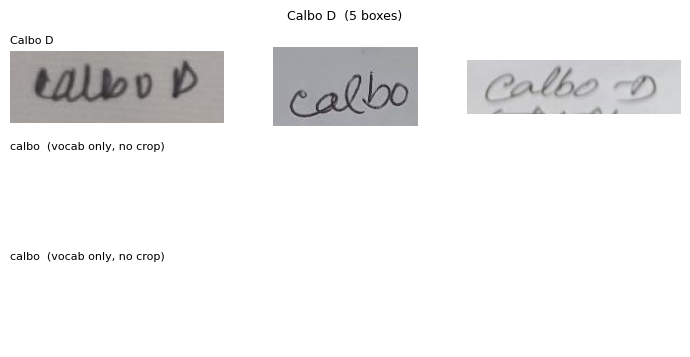

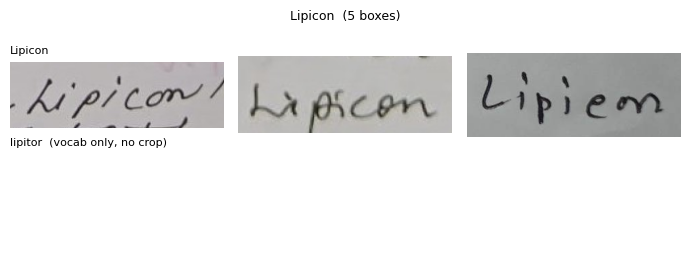

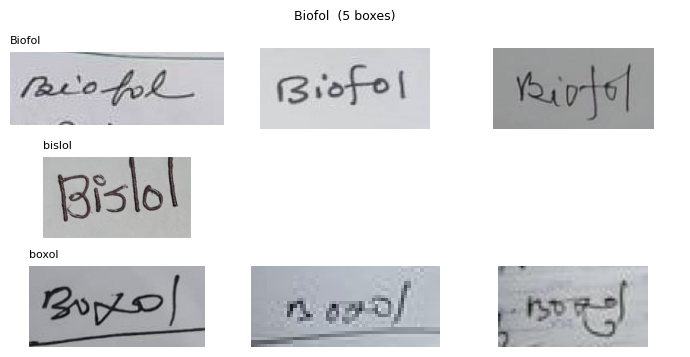

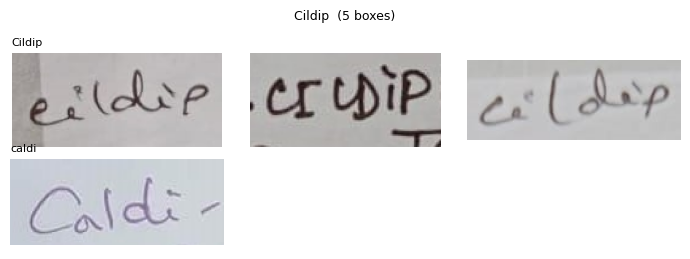

In [18]:
# Near-name review sheet / Cell D5b
REVIEW_MIN_BOXES, MAX_CROPS, PAD = 5, 3, 4
todo = new[(~new["ok_to_add"]) & (new["boxes"] >= REVIEW_MIN_BOXES)].sort_values("boxes", ascending=False)
gt_keys = set(gt["cls"].str.strip().map(key))

def crops_for(cls_name, n=MAX_CROPS):
    sub = gt[gt["cls"].str.strip().map(key) == key(cls_name)].head(n)
    out = []
    for _, r in sub.iterrows():
        if not Path(r.path).exists():
            continue
        im = load_rgb(r.path); W, H = im.size
        out.append(im.crop((max(0, int(r.x0) - PAD), max(0, int(r.y0) - PAD),
                            min(W, int(r.x1) + PAD), min(H, int(r.y1) + PAD))))
    return out

for _, r in todo.iterrows():
    groups = [(r["name"], crops_for(r["name"]))]
    for nm in [x for x in r["near"].split(", ") if x][:3]:
        groups.append((nm if nm in gt_keys else nm + "  (vocab only, no crop)", crops_for(nm)))
    fig, axes = plt.subplots(len(groups), MAX_CROPS, figsize=(7, 1.0 * len(groups) + 0.6), squeeze=False)
    for ax_row, (t, cs) in zip(axes, groups):
        for j, ax in enumerate(ax_row):
            ax.axis("off")
            if j < len(cs):
                ax.imshow(cs[j])
        ax_row[0].set_title(t, fontsize=8, loc="left")
    fig.suptitle(f'{r["name"]}  ({r["boxes"]} boxes)', fontsize=9)
    plt.tight_layout(); plt.show()

In [21]:
# Add reviewed names to the app vocabulary / Cell D5c
import shutil
ADD = [
    "Finix", "Pantonix", "Algin", "Diasulin", "Clopid", "Emistat", "Thyrin", "Thyrox",
    "Maxpro Mups", "Viset", "Remmo", "Bopam", "Myolax", "Etorix", "Napadol", "Rolac",
    "Cotson", "Folison", "Dexlan", "Paricel", "Ezylife", "Docopa", "Cortan", "Solas",
    "Furocef", "Camlodin", "Norium", "Esonix-M", "Deflux", "Bizoran", "Doxiva", "Calbo",
    "Calbo-D", "Lipicon", "Biofol", "Cildif", "Reversair", "Lijenta",
]
VOCAB = WORK / "app" / "vocab.txt"
EXTRA = WORK / "app" / "vocab_additions.txt"
title_case = lambda n: " ".join(w[:1].upper() + w[1:] for w in n.strip().split(" "))
clean = [title_case(n) for n in ADD]

bad = [n for n in clean if set(n) - allowed or len(n) < 3
       or re.search(r"(?i)\b(tab|cap|tablet|capsule)\b", n)]
assert not bad, f"fix these first: {bad}"

cur = [ln.strip() for ln in VOCAB.read_text(encoding="utf-8").splitlines() if ln.strip()]
have = {n.lower() for n in cur}
added = [n for n in clean if n.lower() not in have]
print("already in vocabulary:", [n for n in clean if n.lower() in have])
print("adding", len(added), ":", added)

shutil.copy2(VOCAB, RESULTS / "vocab_before_D5c.txt")          # backup
final = sorted(set(cur) | set(added))
VOCAB.write_text("\n".join(final), encoding="utf-8")
EXTRA.write_text("\n".join(sorted(set(clean))), encoding="utf-8")
print("vocabulary size:", len(final))

already in vocabulary: ['Calbo']
adding 37 : ['Finix', 'Pantonix', 'Algin', 'Diasulin', 'Clopid', 'Emistat', 'Thyrin', 'Thyrox', 'Maxpro Mups', 'Viset', 'Remmo', 'Bopam', 'Myolax', 'Etorix', 'Napadol', 'Rolac', 'Cotson', 'Folison', 'Dexlan', 'Paricel', 'Ezylife', 'Docopa', 'Cortan', 'Solas', 'Furocef', 'Camlodin', 'Norium', 'Esonix-M', 'Deflux', 'Bizoran', 'Doxiva', 'Calbo-D', 'Lipicon', 'Biofol', 'Cildif', 'Reversair', 'Lijenta']
vocabulary size: 741


In [12]:
# Oracle-crop read / Cell D6 
# Recognizer on ground-truth crops (no detector): current vocabulary vs current + all Roboflow names.
import gc, re
from collections import namedtuple
sys.path.insert(0, str(WORK / "app"))
import word_reader as wr
for v in ("det_reader", "word_rd"):                       # free GPU memory from Cell D3
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()

# --- pure helpers ---
key = lambda s: re.sub(r"\s+", " ", s.strip().lower())    # same as Cell D5

def summarise(readings, sel, tag):
    rows = []
    for label, mask in (("name in current vocab", sel["known"].values), ("name NOT in current vocab", ~sel["known"].values)):
        idx = np.where(mask)[0]
        if len(idx) == 0:
            continue
        truth = sel["key"].values[idx]
        pred = np.array([key(readings[i].name) for i in idx])
        top3 = np.array([t in {key(c) for c in readings[i].candidates} for t, i in zip(truth, idx)])
        flagged = np.array([readings[i].flagged for i in idx])
        right, kept = pred == truth, ~flagged
        rows.append({"vocabulary": tag, "boxes": label, "n": len(idx),
                     "top-1 %": round(100 * right.mean(), 1), "top-3 %": round(100 * top3.mean(), 1),
                     "flagged %": round(100 * flagged.mean(), 1), "accepted": int(kept.sum()),
                     "accepted & wrong": int((kept & ~right).sum()),
                     "accuracy on accepted %": round(100 * right[kept].mean(), 1) if kept.any() else None})
    return rows
# --- end helpers ---

N_UNKNOWN = 300                  # boxes whose name is not in the vocabulary: random sample (all known-name boxes are used)
PAD = 4
vocab_now = [ln.strip() for ln in (WORK / "app" / "vocab.txt").read_text(encoding="utf-8").splitlines() if ln.strip()]
keys_now = {key(n) for n in vocab_now}
gt["key"] = gt["cls"].map(key)
gt["known"] = gt["key"].isin(keys_now)
sel = pd.concat([gt[gt["known"]], gt[~gt["known"]].sample(min(N_UNKNOWN, int((~gt["known"]).sum())), random_state=0)]
                ).reset_index(drop=True)

crops = [None] * len(sel)
bad = []
for path, idx in sel.groupby("path").groups.items():
    if not Path(path).exists():
        continue
    img = load_rgb(path); W, H = img.size
    for i in idx:
        r = sel.loc[i]
        x0, y0 = max(0, int(r.x0) - PAD), max(0, int(r.y0) - PAD)
        x1, y1 = min(W, int(r.x1) + PAD), min(H, int(r.y1) + PAD)
        if x1 - x0 < 4 or y1 - y0 < 4:                    # box lies outside (or barely inside) the image
            bad.append((Path(path).name[:25], (round(r.x0), round(r.y0), round(r.x1), round(r.y1)), (W, H)))
            continue
        crops[i] = img.crop((x0, y0, x1, y1))
if bad:
    print(len(bad), "boxes skipped (outside the image), e.g.:", bad[:5])
keep = [c is not None and min(c.size) >= 4 for c in crops]
sel = sel[keep].reset_index(drop=True); crops = [c for c, k in zip(crops, keep) if k]
print("boxes:", len(sel), "| name in current vocab:", int(sel["known"].sum()), "| not in vocab:", int((~sel["known"]).sum()))

def read_all(vocab_list, tag):
    vf = RESULTS / f"vocab_eval_{tag}.txt"
    vf.write_text("\n".join(vocab_list), encoding="utf-8")
    old = wr.VOCAB; wr.VOCAB = vf                          # WordReader reads wr.VOCAB when it is created
    try:
        reader = wr.WordReader()
    finally:
        wr.VOCAB = old
    out = reader.read(crops)
    del reader; gc.collect(); torch.cuda.empty_cache()
    return out

vocab_all = sorted(set(vocab_now) | set(gt["cls"].str.strip()))
reads_now = read_all(vocab_now, "current")
reads_all = read_all(vocab_all, "plus_roboflow")

oracle = pd.DataFrame(summarise(reads_now, sel, f"current ({len(vocab_now)})") +
                      summarise(reads_all, sel, f"current + Roboflow ({len(vocab_all)})"))
print(oracle.to_string(index=False))
oracle.to_csv(RESULTS / "results_oracle_crops.csv", index=False)

per_box = sel[["path", "cls", "known"]].copy()
for tag, rd in (("now", reads_now), ("all", reads_all)):
    per_box[f"raw_{tag}"] = [r.raw for r in rd]; per_box[f"name_{tag}"] = [r.name for r in rd]
    per_box[f"margin_{tag}"] = [round(r.margin, 2) for r in rd]; per_box[f"flagged_{tag}"] = [r.flagged for r in rd]
per_box.to_csv(RESULTS / "oracle_crop_reads.csv", index=False)

boxes: 519 | name in current vocab: 219 | not in vocab: 300
No Transformation module specified
No Transformation module specified
               vocabulary                     boxes   n  top-1 %  top-3 %  flagged %  accepted  accepted & wrong  accuracy on accepted %
            current (704)     name in current vocab 219     88.1     93.6       39.3       133                 2                    98.5
            current (704) name NOT in current vocab 300      0.0      0.0       94.3        17                17                     0.0
current + Roboflow (1466)     name in current vocab 219     83.6     92.2       46.6       117                 2                    98.3
current + Roboflow (1466) name NOT in current vocab 300     80.3     87.7       54.7       136                 3                    97.8


In [16]:
#Scratch cell (See how many files are affected by rotation)
rot = {}
for p in gt["path"].unique():
    o = Image.open(p).getexif().get(274, 1)       # 274 = EXIF Orientation
    if o != 1:
        rot[p] = o
print(len(rot), "of", gt["path"].nunique(), "images carry an EXIF orientation tag |", pd.Series(rot).value_counts().to_dict())
rot_df = (pd.DataFrame({"file": [Path(p).name for p in rot], "orientation": list(rot.values())})
            .sort_values(["orientation", "file"]))
print(rot_df.to_string(index=False))
rot_df.to_csv(RESULTS / "exif_rotated_roboflow.csv", index=False)

33 of 378 images carry an EXIF orientation tag | {8: 21, 6: 9, 3: 3}
                                                                            file  orientation
282563301_3255698567998900_8916645825358876773_n_jpg.rf.StGjdz6ZOSbz21p050EJ.jpg            3
 337615949_607019757944055_5853517974099392715_n_jpg.rf.5zfi1Qay7xWvXtndP3zd.jpg            3
      WhatsApp Image 2023-04-09 at 12-31-02 PM_jpeg.rf.UefcGeduanoNxfu3kgn6.jpeg            3
282318487_3255698454665578_5626942700711677563_n_jpg.rf.2OAYDrBYqvoKumW9JzOd.jpg            6
292257889_3291494104419346_1847424128365425288_n_jpg.rf.K5NPn8BMlOvYF5gbLuj6.jpg            6
 336619155_182549424562875_7600598552472446473_n_jpg.rf.l3Z4KwxJZmWV0q2eDVQd.jpg            6
 338303481_545552644230892_2245226500914916769_n_jpg.rf.3MYdO499bFq7KSNn3PNY.jpg            6
 338306871_231644472689717_5424517991767742827_n_jpg.rf.Hhlt4cAYmITPA558NN3z.jpg            6
       WhatsApp Image 2023-03-23 at 8-59-09 PM_jpeg.rf.K9NaTmu3fIULf8gNnnCG.jpeg     

In [15]:
# Class-grouped vocabulary split / Cell D7  (04_detection)
# Deployment-like test: the vocabulary holds most Roboflow names; the test names are held out by CLASS.
# Needs Cell D6 run first in this kernel (it defines sel, crops, read_all, vocab_now, keys_now, reads_now, key).
assert len(reads_now) == len(sel), "run Cell D6 first"

# --- pure helpers ---
def split_classes(sel):
    """split the classes of the not-in-vocabulary boxes into two halves, balanced by box count"""
    counts = sel.loc[~sel["known"], "key"].value_counts()
    half, load = {}, [0, 0]
    for c, n in counts.items():
        h = int(np.argmin(load)); half[c] = h; load[h] += n
    return np.where(sel["known"], -1, sel["key"].map(half).fillna(-1)).astype(int)

def metrics_row(parts, sel, label, n_vocab, B=2000, seed=0):
    """parts = [(readings, box_index_array), ...]; confidence intervals resample CLASSES, not boxes"""
    truth = np.concatenate([sel["key"].values[i] for _, i in parts])
    reads = [rd[j] for rd, i in parts for j in i]
    pred = np.array([key(r.name) for r in reads])
    top3 = np.array([t in {key(c) for c in r.candidates} for t, r in zip(truth, reads)])
    flagged = np.array([r.flagged for r in reads])
    right, kept = pred == truth, ~flagged
    wrong_acc = kept & ~right
    cls_ids, inv = np.unique(truth, return_inverse=True)
    K = len(cls_ids)
    per = lambda v: np.bincount(inv, weights=np.asarray(v, float), minlength=K)
    n_c = per(np.ones(len(truth)))
    idx = np.random.default_rng(seed).integers(0, K, (B, K))
    def ci(v):
        lo, hi = np.percentile(per(v)[idx].sum(1) / n_c[idx].sum(1), [2.5, 97.5]) * 100
        return f"{100 * np.mean(v):.1f} [{lo:.1f}, {hi:.1f}]"
    return {"boxes": label, "vocab": n_vocab, "n": len(truth), "classes": K,
            "top-1 % [95% CI]": ci(right), "top-1 per-class avg %": round(100 * (per(right) / n_c).mean(), 1),
            "top-3 %": round(100 * top3.mean(), 1), "flagged %": round(100 * flagged.mean(), 1),
            "accepted": int(kept.sum()), "accepted & wrong": int(wrong_acc.sum()),
            "wrong-accepted % of boxes [95% CI]": ci(wrong_acc)}
# --- end helpers ---

sel["half"] = split_classes(sel)
known_idx = np.where(sel["half"] == -1)[0]
new_idx = np.where(sel["half"] >= 0)[0]
print("known-name boxes:", len(known_idx), "| new-name boxes:", len(new_idx),
      "| half sizes (boxes):", [int((sel["half"] == h).sum()) for h in (0, 1)])

rob = {}                                                   # every Roboflow name that is not already in the vocabulary
for n in gt["cls"].str.strip():
    if key(n) not in keys_now:
        rob.setdefault(key(n), n)

store, vsize = {}, {}
for h in (0, 1):                                           # fold h: the names of half h are removed from the vocabulary
    held = set(sel.loc[sel["half"] == h, "key"])
    vocab_h = vocab_now + [n for k, n in rob.items() if k not in held]
    vsize[h] = len(vocab_h)
    print(f"fold {h}: vocabulary {len(vocab_h)} names, {len(held)} test classes held out")
    store[h] = read_all(vocab_h, f"split_h{h}")

in_parts = [(store[h], np.where(sel["half"] == 1 - h)[0]) for h in (0, 1)]    # new names that ARE in the list
out_parts = [(store[h], np.where(sel["half"] == h)[0]) for h in (0, 1)]       # new names held out
vs = f"{vsize[0]}/{vsize[1]}"
rows = [metrics_row([(reads_now, known_idx)], sel, "original names, current vocab only", len(vocab_now)),
        metrics_row([(store[0], known_idx)], sel, "original names, fold 0 vocab", vsize[0]),
        metrics_row([(store[1], known_idx)], sel, "original names, fold 1 vocab", vsize[1]),
        metrics_row([(reads_now, new_idx)], sel, "new names, NOT in list (current vocab only)", len(vocab_now)),
        metrics_row(in_parts, sel, "new names, IN list (never trained)", vs),
        metrics_row(out_parts, sel, "new names, HELD OUT of a larger vocab", vs)]
split_eval = pd.DataFrame(rows)
print(split_eval.to_string(index=False))
split_eval.to_csv(RESULTS / "results_vocab_split.csv", index=False)

known-name boxes: 219 | new-name boxes: 300 | half sizes (boxes): [150, 150]
fold 0: vocabulary 1346 names, 120 test classes held out
No Transformation module specified
fold 1: vocabulary 1345 names, 121 test classes held out
No Transformation module specified
                                      boxes     vocab   n  classes  top-1 % [95% CI]  top-1 per-class avg %  top-3 %  flagged %  accepted  accepted & wrong wrong-accepted % of boxes [95% CI]
         original names, current vocab only       704 219       69 88.1 [84.6, 92.0]                   90.8     93.6       39.3       133                 2                     0.9 [0.0, 2.6]
               original names, fold 0 vocab      1346 219       69 84.9 [80.6, 89.4]                   87.6     92.7       45.2       120                 2                     0.9 [0.0, 2.6]
               original names, fold 1 vocab      1345 219       69 84.0 [79.8, 88.5]                   85.9     93.2       46.1       118                 2           

In [22]:
# Veto test on oracle crops / Cell D8
def veto_grid(raw_len, dis, margin, correct, thr=2.30,
              lens=(0, 3, 4, 5), dmaxs=(9.0, 0.8, 0.6, 0.5, 0.4)):
    rows = []
    for L in lens:
        for D in dmaxs:
            acc = (margin >= thr) & (raw_len >= L) & (dis <= D)
            rows.append({"min raw length": L, "max disagreement": "off" if D >= 9 else D,
                         "accepted": int(acc.sum()), "wrong accepted": int((acc & ~correct).sum()),
                         "correct accepted": int((acc & correct).sum())})
    return pd.DataFrame(rows)
pb = per_box.copy()
strip = lambda s: re.sub(r"^(tab|cap)\.?\s+", "", s.strip(), flags=re.I).lower()
raw_len = pb["raw_now"].map(lambda s: len(strip(s))).values
dis = np.array([edit_distance(strip(r), n.lower()) / max(len(n), 1) for r, n in zip(pb["raw_now"], pb["name_now"])])
correct = (pb["name_now"].map(key) == pb["cls"].str.strip().map(key)).values
print(veto_grid(raw_len, dis, pb["margin_now"].values, correct).to_string(index=False))

 min raw length max disagreement  accepted  wrong accepted  correct accepted
              0              off       150              19               131
              0              0.8       150              19               131
              0              0.6       149              19               130
              0              0.5       147              19               128
              0              0.4       139              18               121
              3              off       149              19               130
              3              0.8       149              19               130
              3              0.6       148              19               129
              3              0.5       146              19               127
              3              0.4       138              18               120
              4              off       147              18               129
              4              0.8       147              18               129

In [23]:
# End-to-end page evaluation / Cell D9
import importlib
importlib.reload(wr)                                   # picks up the edited word_reader.py
N_PAGES, PAD = 20, 4                                   # raise N_PAGES once it works; expect several minutes per 20 pages
vocab_all_now = [ln.strip() for ln in (WORK / "app" / "vocab.txt").read_text(encoding="utf-8").splitlines() if ln.strip()]
print("vocabulary names the gate would veto:", [n for n in vocab_all_now if wr.non_name_reason(n)])
vkeys = {key(n) for n in vocab_all_now}

for v in ("det_reader", "word_rd"):
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()
det_reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)   # used by detect_boxes (Cell D1)
word_rd = wr.WordReader()

rows = []
for path in sorted(gt["path"].unique())[:N_PAGES]:
    if not Path(path).exists():
        continue
    img = load_rgb(path); W, H = img.size
    G = gt[gt["path"] == path]
    boxes = [b for b in detect_boxes(np.array(img)) if b[3] - b[1] >= 12 and b[2] - b[0] >= 24]
    if not boxes:
        continue
    crops = [img.crop((max(0, x0 - PAD), max(0, y0 - PAD), min(W, x1 + PAD), min(H, y1 + PAD)))
             for x0, y0, x1, y1 in boxes]
    iou = iou_matrix(G[["x0", "y0", "x1", "y1"]].values, boxes)      # [GT, detections]
    inside = centers_inside(boxes, G[["x0", "y0", "x1", "y1"]].values)
    for i, r in enumerate(word_rd.read(crops, gate=False)):
        j = int(iou[:, i].argmax()) if iou[:, i].max() >= 0.3 else (int(inside[i].argmax()) if inside[i].any() else -1)
        truth = key(G.iloc[j]["cls"]) if j >= 0 else None
        rows.append({"page": Path(path).name, "box": i, "raw": r.raw, "name": r.name,
                     "margin": round(r.margin, 2), "accepted": not r.flagged, "reason": r.reason,
                     "truth": truth, "truth_in_vocab": (truth in vkeys) if truth else None,
                     "correct": truth is not None and key(r.name) == truth})
e2e = pd.DataFrame(rows)
e2e.to_csv(RESULTS / "e2e_page_reads.csv", index=False)

acc = e2e["accepted"]
def rule(mask, label):
    d = e2e[mask]
    return {"rule": label, "accepted": len(d), "correct": int(d["correct"].sum()),
            "wrong name on a labelled box": int((d["truth"].notna() & ~d["correct"]).sum()),
            "accepted on unlabelled boxes": int(d["truth"].isna().sum())}
out = [rule(acc, "baseline (margin >= 2.30)"), rule(acc & e2e["reason"].isna(), "+ not-a-name gate")]
for rs in sorted(e2e["reason"].dropna().unique()):
    out.append(rule(acc & (e2e["reason"] != rs), f"baseline minus '{rs}' vetoes only"))
for th in (3.0, 4.0, 5.0):
    out.append(rule(e2e["margin"] >= th, f"margin >= {th} (exploratory)"))
print(pd.DataFrame(out).to_string(index=False))
print(e2e[acc & e2e["truth"].isna()][["page", "raw", "name", "margin", "reason"]].head(40).to_string(index=False))

vocabulary names the gate would veto: ['Az', 'Rablet']
No Transformation module specified
                                       rule  accepted  correct  wrong name on a labelled box  accepted on unlabelled boxes
                  baseline (margin >= 2.30)        23       11                             2                            10
                          + not-a-name gate        14       11                             2                             1
baseline minus 'form_word_only' vetoes only        23       11                             2                            10
   baseline minus 'header_word' vetoes only        19       11                             2                             6
 baseline minus 'mostly_digits' vetoes only        23       11                             2                            10
     baseline minus 'too_short' vetoes only        18       11                             2                             5
                margin >= 3.0 (exploratory)      